# 2. Data Preprocessing and Feature Selection

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.5f}'.format)

Load the tools needed for preprocessing and charts. Numbers are shown as normal values (like 3,810,113.98854) instead of scientific notation (3.810114e+06).

## Read the cleaned data

In [2]:
data = pd.read_csv('cleaned_data.csv')
data.head()

,neo,pha,H,diameter,albedo,e,a,q,i,om,w,ma,ad,n,per,per_y,moid,moid_ld,class
0,N,N,3.40000,939.40000,0.09000,0.07601,2.76917,2.55868,10.59407,80.30553,73.59769,77.37210,2.97965,0.21389,"1,683.14570",4.60820,1.59478,620.64053,MBA
1,N,N,4.20000,545.00000,0.10100,0.22997,2.77384,2.13593,34.83293,173.02474,310.20239,144.97568,3.41175,0.21334,"1,687.41099",4.61988,1.23429,480.34864,MBA
2,N,N,5.33000,246.59600,0.21400,0.25694,2.66829,1.98271,12.99104,169.85148,248.06619,125.43535,3.35386,0.22613,"1,592.01377",4.35870,1.03429,402.51464,MBA
3,N,N,3.00000,525.40000,0.42280,0.08872,2.36142,2.15191,7.14177,103.81080,150.72854,95.86194,2.57093,0.27161,"1,325.43276",3.62884,1.13948,443.45143,MBA
4,N,N,6.90000,106.69900,0.27400,0.19091,2.57404,2.08262,5.36743,141.57103,358.64842,17.84634,3.06546,0.23866,"1,508.41442",4.12981,1.09575,426.43303,MBA


Start from the cleaned data saved by notebook 1.

In [3]:
data.shape

(932336, 19)

Confirm the cleaned size (932,336 rows, 19 columns).

## Encode Y/N columns to 1/0

In [4]:
data['pha'] = data['pha'].map({'Y': 1, 'N': 0})
data['neo'] = data['neo'].map({'Y': 1, 'N': 0})
data[['pha', 'neo']].value_counts()

pha  neo
0    0      909453
     1       20817
1    1        2066
Name: count, dtype: int64

Models only understand numbers, so Y/N labels are turned into 1/0.

## Skewness before transformation

In [5]:
skew_cols = ['H', 'e', 'a', 'q', 'i', 'ad', 'n', 'per', 'per_y', 'moid', 'moid_ld', 'diameter', 'albedo']
data[skew_cols].skew().sort_values()

H            0.62710
albedo       1.64768
e            1.90947
i            2.21490
n            5.65350
q           15.65513
moid        15.71322
moid_ld     15.71322
diameter    25.56060
a          847.53535
ad         852.60532
per        939.89849
per_y      939.89849
dtype: float64

Measure skewness first so we know which columns need a transform.

## Log transform for highly right-skewed columns

In [6]:
log_cols = ['a', 'q', 'ad', 'n', 'per', 'per_y', 'moid', 'moid_ld', 'diameter', 'albedo']

df = data.copy()
for col in log_cols:
    df[col] = np.log1p(df[col])

df[log_cols].skew().sort_values()

moid_ld    -3.70438
albedo      1.33625
diameter    1.53916
n           3.52299
moid        3.78816
q           5.36298
per         6.26307
per_y       8.23915
a           8.69802
ad          8.82485
dtype: float64

Log shrinks very long tails so extreme values do not dominate the models.

## Compare transforms for a (Box-Cox is closest to 0, log is used because it is simple and easy to repeat in the app)

In [7]:
from scipy import stats

print('original :', round(data['a'].skew(), 2))
print('sqrt     :', round(np.sqrt(data['a']).skew(), 2))
print('cbrt     :', round(np.cbrt(data['a']).skew(), 2))
print('log      :', round(np.log1p(data['a']).skew(), 2))
print('boxcox   :', round(pd.Series(stats.boxcox(data['a'])[0]).skew(), 2))

original : 847.54
sqrt     : 97.69
cbrt     : 20.83
log      : 8.7


boxcox   : -0.93


Compare 4 transforms on a to justify why log was chosen.

## Histograms after log transform

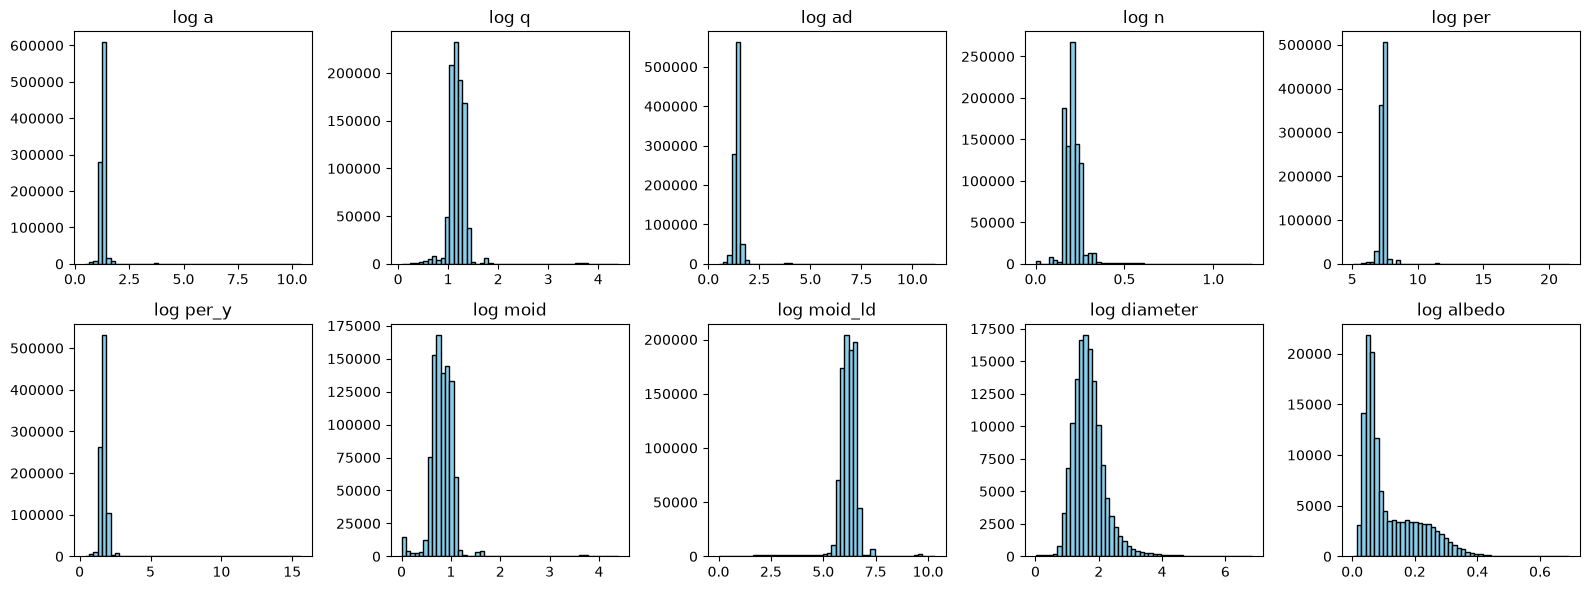

In [8]:
plt.figure(figsize=(16, 6))
for i in range(len(log_cols)):
    plt.subplot(2, 5, i + 1)
    plt.hist(df[log_cols[i]].dropna(), bins=50, color='skyblue', edgecolor='black')
    plt.title('log ' + log_cols[i])
plt.tight_layout()
plt.savefig('images/after_log_transform.png')
plt.show()

Check visually that the log transform made the columns easier to model.

## Angles (om, w, ma) are cyclic: 0 and 360 are the same, so use sin and cos

In [9]:
for col in ['om', 'w', 'ma']:
    df[col + '_sin'] = np.sin(np.radians(df[col]))
    df[col + '_cos'] = np.cos(np.radians(df[col]))

df[['om', 'om_sin', 'om_cos']].head()

,om,om_sin,om_cos
0,80.30553,0.98572,0.16839
1,173.02474,0.12144,-0.99260
2,169.85148,0.17620,-0.98435
3,103.81080,0.97109,-0.23872
4,141.57103,0.62154,-0.78338


Angles wrap around (359 and 1 degree are close), so sin and cos put them on a circle.

## Outliers: IQR count after log transform

In [10]:
check_cols = ['H', 'e', 'a', 'i', 'q', 'ad', 'per_y', 'moid']
for col in check_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    count = len(df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)])
    print(col, ':', count)

H : 39672
e : 24603
a : 22918
i : 29294
q : 33783
ad : 37663
per_y : 22810


moid : 34177


Count outliers again after log to see how much the transform helped.

## PHA rows that are IQR outliers (removing outliers would remove hazardous asteroids)

In [11]:
Q1 = df['e'].quantile(0.25)
Q3 = df['e'].quantile(0.75)
IQR = Q3 - Q1
e_outliers = df[(df['e'] < Q1 - 1.5 * IQR) | (df['e'] > Q3 + 1.5 * IQR)]

print('Total PHA            :', df['pha'].sum())
print('PHA inside e outliers:', e_outliers['pha'].sum())

Total PHA            : 2066
PHA inside e outliers: 1687


Check how many PHAs are outliers, to see what removing outliers would do to the target.

# Feature selection - Case 1 (pha)

## Leakage columns removed: moid, moid_ld (define pha), q, ad (near duplicates of moid / neo), neo, class, diameter, albedo (mostly empty)

In [12]:
clf_candidates = ['H', 'e', 'a', 'i', 'n', 'per_y',
                  'om_sin', 'om_cos', 'w_sin', 'w_cos', 'ma_sin', 'ma_cos']

X = df[clf_candidates]
y = df['pha']
X.shape

(932336, 12)

List the candidate features for pha (leakage columns already removed).

## Method 1 - Correlation between features

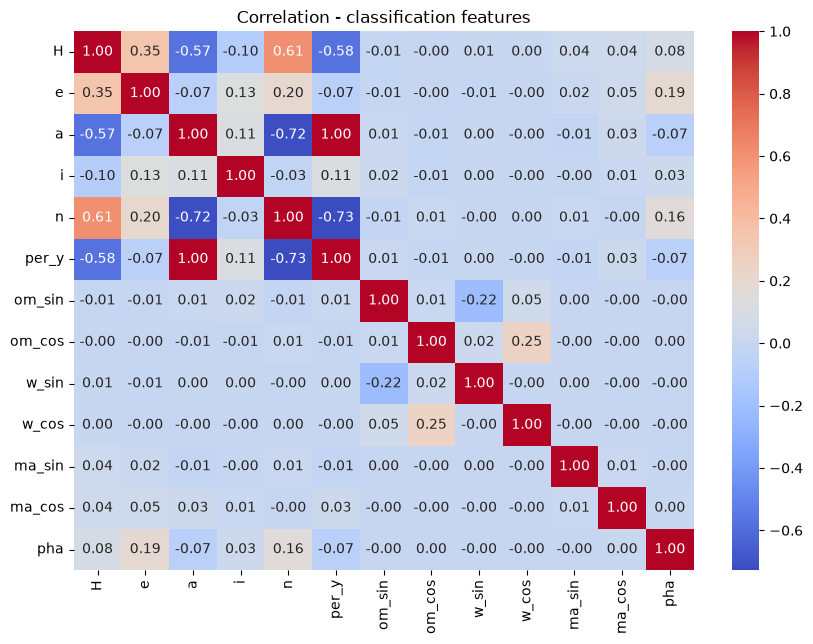

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[clf_candidates + ['pha']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation - classification features')
plt.savefig('images/corr_classification.png')
plt.show()

Correlation shows which candidate features repeat each other.

## Method 2 - Statistical test (ANOVA F-test)

In [14]:
from sklearn.feature_selection import f_classif

f_values, p_values = f_classif(X, y)
anova_df = pd.DataFrame({'Feature': clf_candidates, 'F_score': f_values, 'p_value': p_values})
anova_df.sort_values('F_score', ascending=False)

,Feature,F_score,p_value
1,e,"35,339.18034",0.00000
4,n,"24,838.44409",0.00000
0,H,"6,499.58865",0.00000
5,per_y,"5,029.21851",0.00000
2,a,"4,872.97327",0.00000
3,i,"1,103.73787",0.00000
6,om_sin,9.48900,0.00207
11,ma_cos,6.46708,0.01099
9,w_cos,3.95832,0.04664
10,ma_sin,1.16624,0.28017


ANOVA F-test checks statistically if each feature differs between PHA and non-PHA.

## Take a balanced sample for faster feature selection

In [15]:
pha_rows = df[df['pha'] == 1]
non_pha_rows = df[df['pha'] == 0].sample(50000, random_state=42)
small = pd.concat([pha_rows, non_pha_rows])

X_small = small[clf_candidates]
y_small = small['pha']
y_small.value_counts()

pha
0    50000
1     2066
Name: count, dtype: int64

A balanced sample (all PHAs + 50,000 others) makes the next methods fast and fair.

## Method 3 - Random Forest feature importance

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_small, y_small)

rf_imp = pd.DataFrame({'Feature': clf_candidates, 'Importance': rf.feature_importances_})
rf_imp = rf_imp.sort_values('Importance', ascending=False)
rf_imp

,Feature,Importance
1,e,0.38297
0,H,0.19956
2,a,0.11300
5,per_y,0.10382
4,n,0.09001
3,i,0.02850
11,ma_cos,0.01888
9,w_cos,0.01573
8,w_sin,0.01347
10,ma_sin,0.01191


Random Forest importance shows which features the tree model actually uses.

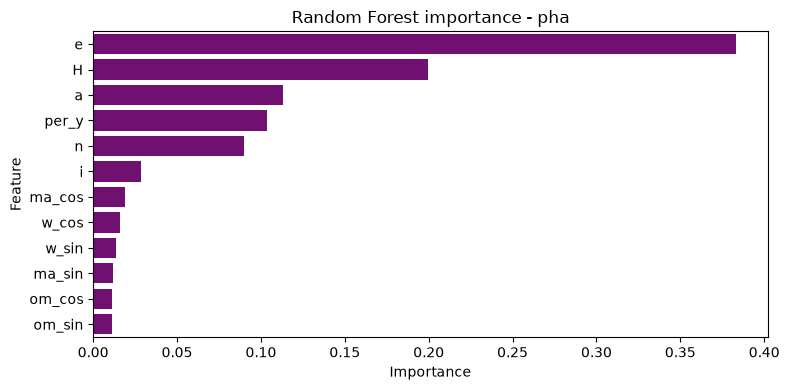

In [17]:
plt.figure(figsize=(8, 4))
sns.barplot(x=rf_imp['Importance'], y=rf_imp['Feature'], color='purple')
plt.title('Random Forest importance - pha')
plt.tight_layout()
plt.savefig('images/rf_importance_pha.png')
plt.show()

A bar chart makes the importance ranking easy to read and present.

## Method 4 - RFE (Recursive Feature Elimination) with Logistic Regression

In [18]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X_small)

rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=6)
rfe.fit(X_scaled, y_small)

rfe_df = pd.DataFrame({'Feature': clf_candidates, 'Selected': rfe.support_, 'Rank': rfe.ranking_})
rfe_df.sort_values('Rank')

,Feature,Selected,Rank
0,H,True,1
1,e,True,1
2,a,True,1
4,n,True,1
5,per_y,True,1
11,ma_cos,True,1
9,w_cos,False,2
6,om_sin,False,3
10,ma_sin,False,4
7,om_cos,False,5


RFE removes the weakest feature one by one; a third opinion on feature ranking.

## Summary of all methods

In [19]:
summary = anova_df[['Feature', 'F_score']].merge(rf_imp, on='Feature').merge(rfe_df[['Feature', 'Rank']], on='Feature')
summary.columns = ['Feature', 'ANOVA_F', 'RF_Importance', 'RFE_Rank']
summary.sort_values('RF_Importance', ascending=False)

,Feature,ANOVA_F,RF_Importance,RFE_Rank
1,e,"35,339.18034",0.38297,1
0,H,"6,499.58865",0.19956,1
2,a,"4,872.97327",0.11300,1
5,per_y,"5,029.21851",0.10382,1
4,n,"24,838.44409",0.09001,1
3,i,"1,103.73787",0.02850,6
11,ma_cos,6.46708,0.01888,1
9,w_cos,3.95832,0.01573,2
8,w_sin,0.33400,0.01347,7
10,ma_sin,1.16624,0.01191,4


Put all methods side by side to choose features by agreement, not by one method.

## Final features for classification: H, e, a, i (n and per_y repeat a; angle features scored very low in all methods)

In [20]:
clf_features = ['H', 'e', 'a', 'i']

classification = data[clf_features + ['pha']]
classification.to_csv('classification.csv', index=False)
classification.shape

(932336, 5)

Save the 4 chosen features + target so the classification notebook can use them.

# Feature selection - Case 2 (diameter)

## Only rows with known diameter and albedo

In [21]:
reg_df = df.dropna(subset=['diameter', 'albedo'])
reg_df.shape

(131237, 25)

Diameter is known for only some asteroids, so Case 2 uses only those rows.

In [22]:
reg_candidates = ['H', 'albedo', 'e', 'a', 'q', 'i', 'ad', 'n', 'per_y', 'moid',
                  'om_sin', 'om_cos', 'w_sin', 'w_cos', 'ma_sin', 'ma_cos']

X = reg_df[reg_candidates]
y = reg_df['diameter']

List the candidate features for diameter.

## Method 1 - Correlation with diameter (log)

In [23]:
reg_df[reg_candidates + ['diameter']].corr()['diameter'].sort_values()

H          -0.83041
n          -0.50356
albedo     -0.28839
e          -0.16838
w_sin      -0.00644
om_sin     -0.00324
ma_sin     -0.00084
om_cos      0.00021
w_cos       0.00208
ma_cos      0.00238
i           0.13690
ad          0.45314
q           0.51782
moid        0.52212
a           0.53138
per_y       0.53330
diameter    1.00000
Name: diameter, dtype: float64

Correlation with diameter shows which features move with size.

## Method 2 - Statistical test (F-test for regression)

In [24]:
from sklearn.feature_selection import f_regression

f_values, p_values = f_regression(X, y)
f_reg_df = pd.DataFrame({'Feature': reg_candidates, 'F_score': f_values, 'p_value': p_values})
f_reg_df.sort_values('F_score', ascending=False)

,Feature,F_score,p_value
0,H,"291,527.08455",0.00000
8,per_y,"52,160.18599",0.00000
3,a,"51,636.31144",0.00000
9,moid,"49,183.22746",0.00000
4,q,"48,080.45301",0.00000
7,n,"44,582.76913",0.00000
6,ad,"33,909.43484",0.00000
1,albedo,"11,904.62770",0.00000
2,e,"3,829.50823",0.00000
5,i,"2,506.42418",0.00000


F-test for regression checks statistically which features explain diameter.

## Method 3 - Random Forest feature importance

In [25]:
from sklearn.ensemble import RandomForestRegressor

X_small = X.sample(30000, random_state=42)
y_small = y.loc[X_small.index]

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_small, y_small)

rf_imp_reg = pd.DataFrame({'Feature': reg_candidates, 'Importance': rf.feature_importances_})
rf_imp_reg = rf_imp_reg.sort_values('Importance', ascending=False)
rf_imp_reg

,Feature,Importance
0,H,0.75268
1,albedo,0.21179
3,a,0.00504
9,moid,0.00444
7,n,0.00355
8,per_y,0.00304
4,q,0.00279
5,i,0.00251
14,ma_sin,0.00193
6,ad,0.00189


Random Forest importance for diameter on a 30,000 sample for speed.

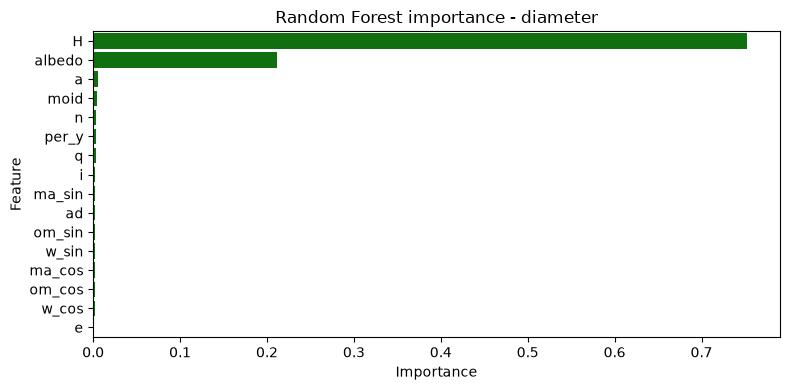

In [26]:
plt.figure(figsize=(8, 4))
sns.barplot(x=rf_imp_reg['Importance'], y=rf_imp_reg['Feature'], color='green')
plt.title('Random Forest importance - diameter')
plt.tight_layout()
plt.savefig('images/rf_importance_diameter.png')
plt.show()

Bar chart of the diameter feature importance.

## Method 4 - RFE with Linear Regression

In [27]:
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X_small)

rfe = RFE(LinearRegression(), n_features_to_select=6)
rfe.fit(X_scaled, y_small)

rfe_reg_df = pd.DataFrame({'Feature': reg_candidates, 'Selected': rfe.support_, 'Rank': rfe.ranking_})
rfe_reg_df.sort_values('Rank')

,Feature,Selected,Rank
0,H,True,1
1,albedo,True,1
3,a,True,1
7,n,True,1
6,ad,True,1
8,per_y,True,1
2,e,False,2
9,moid,False,3
4,q,False,4
5,i,False,5


RFE with Linear Regression as another ranking method for diameter.

## Final features for regression: H, albedo, a, i (n, per_y, ad, q, moid repeat a; angles and e scored very low)

In [28]:
reg_features = ['H', 'albedo', 'a', 'i']

regression = data.dropna(subset=['diameter', 'albedo'])[reg_features + ['diameter']]
regression.to_csv('regression.csv', index=False)
regression.shape

(131237, 5)

Save the 4 chosen features + diameter for the regression notebook.

# Case 3 (clustering) data

In [29]:
clustering = data[['a', 'e', 'i', 'per', 'moid_ld', 'class', 'pha', 'neo']]
clustering.to_csv('clustering.csv', index=False)
clustering.shape

(932336, 8)

Save the clustering columns (and labels only for checking) for the clustering notebook.